In [1]:
%pip install gensim


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [2]:
! pip install scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [3]:
import numpy as np
import gensim
from gensim.models import Word2Vec

print("NumPy:", np.__version__)
print("Gensim:", gensim.__version__)

NumPy: 2.5.4
Gensim: 4.4.0


In [4]:
%pip install numpy pandas nltk scikit-learn


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip
Note: you may need to restart the kernel to use updated packages.


In [5]:
import re
import warnings
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd

import nltk
from nltk.corpus import stopwords
from nltk.stem import WordNetLemmatizer

from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.decomposition import PCA
from sklearn.naive_bayes import MultinomialNB
from sklearn.cluster import KMeans
from sklearn.metrics import accuracy_score, precision_score

from gensim.models import Word2Vec

nltk.download("stopwords", quiet=True)
nltk.download("wordnet", quiet=True)
nltk.download("omw-1.4", quiet=True)

train_df = pd.read_csv("https://s3.ap-south-1.amazonaws.com/new-assets.ccbp.in/frontend/content/aiml/classical-ml/train.csv")
test_df = pd.read_csv("https://s3.ap-south-1.amazonaws.com/new-assets.ccbp.in/frontend/content/aiml/classical-ml/test.csv")

print(f"Train: {train_df.shape}")
print(f"Test: {test_df.shape}")
train_df.head()

Train: (9232, 3)
Test: (2309, 3)


,text,airline,label
0,@JetBlue Finally starting to come out. 40 minu...,Delta,0
1,@USAirways oh I got right through to an agent....,US Airways,0
2,@AmericanAir any idea on what the wait time is...,American,0
3,@AmericanAir Priority baggage evidently means ...,American,0
4,@USAirways you're really fudgin up with all th...,US Airways,0


In [6]:
train_df.duplicated().sum()

np.int64(98)

In [7]:
final = train_df.drop_duplicates(subset = {"text","airline","label"})


In [8]:
final.duplicated().sum()

np.int64(0)

In [9]:
! pip install beautifulsoup4


[notice] A new release of pip is available: 25.0.1 -> 26.2.2
[notice] To update, run: pip install --upgrade pip


In [10]:
from bs4 import BeautifulSoup

In [11]:
cleaning_text = final['text']

In [12]:
final['text']

0       @JetBlue Finally starting to come out. 40 minu...
1       @USAirways oh I got right through to an agent....
2       @AmericanAir any idea on what the wait time is...
3       @AmericanAir Priority baggage evidently means ...
4       @USAirways you're really fudgin up with all th...
                              ...                        
9227    @AmericanAir you have my money, you change my ...
9228    @USAirways between 3 of us, it is costing over...
9229    @USAirways No flights out of Philly because of...
9230    @united customer service sucks!  They hang up ...
9231    @USAirways I paid for my seat.  I expect to be...
Name: text, Length: 9134, dtype: str

In [13]:
keep_words = {
    "no", "not", "nor", "never", "neither",
    "very", "too", "more", "most", "less", "least",
    "only", "just", "so", "too",
    "don't", "doesn't", "didn't",
    "isn't", "aren't", "wasn't", "weren't",
    "haven't", "hasn't", "hadn't",
    "won't", "wouldn't", "can't", "couldn't",
    "shouldn't", "mustn't", "needn't",
    "don", "doesn", "didn", "isn", "aren",
    "wasn", "weren", "haven", "hasn", "hadn",
    "won", "wouldn", "couldn", "shouldn",
    "mustn", "needn"
}
stop_words = set(stopwords.words("english")) - keep_words

In [14]:
from tqdm import tqdm 
preprocessed_reviews = [] 
for sentence in tqdm(final['text'].values):
  text = str(sentence).lower()
  text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
  text = re.sub(r"http\S+|www\S+", "", text)
  text = re.sub(r'\S*\d\S*', '', text).strip()
  text = re.sub(r'@\W+', '', text)
  text = re.sub(r'\s+', ' ', text).strip() 
  text = BeautifulSoup(text, "html.parser").get_text()
  text = ' '.join(e for e in text.split() if e not in stop_words)  
  preprocessed_reviews.append(text.strip())

  

100%|██████████| 9134/9134 [00:00<00:00, 36281.75it/s]


In [15]:
final['cleaned_text'] = preprocessed_reviews

In [16]:
final['cleaned_text'].head(30)

0     jetblue finally starting come minutes no commu...
1     usairways oh got right agent just kept putting...
2     americanair idea wait time refunds usairways t...
3     americanair priority baggage evidently means c...
4     usairways youre really fudgin delays justwantm...
5     americanair supposed depart central ready clos...
6     americanair guys dfw stuck gate half hour pull...
7     united exhausted amp frustrated link fb post a...
8     usairways already let know sent complaints got...
9     usairways guys luggage san jose supposed deliv...
10           jetblue loving capt joe flight bos sfo fun
11                   usairways joke stop losing luggage
12    united traveling megzezzo injured gate agent c...
13    americanair im still patiently waiting respons...
14                        southwestair one heck airline
15    united hey thanks helping miss buddies bday gu...
16    southwestair flight boston tmrw cancelled flig...
17            southwestair yep two hours thirty 

In [17]:
final

,text,airline,label,cleaned_text
0,@JetBlue Finally starting to come out. 40 minu...,Delta,0,jetblue finally starting come minutes no commu...
1,@USAirways oh I got right through to an agent....,US Airways,0,usairways oh got right agent just kept putting...
2,@AmericanAir any idea on what the wait time is...,American,0,americanair idea wait time refunds usairways t...
3,@AmericanAir Priority baggage evidently means ...,American,0,americanair priority baggage evidently means c...
4,@USAirways you're really fudgin up with all th...,US Airways,0,usairways youre really fudgin delays justwantm...
...,...,...,...,...
9227,"@AmericanAir you have my money, you change my ...",American,0,americanair money change flight dont answer ph...
9228,"@USAirways between 3 of us, it is costing over...",US Airways,0,usairways us costing get home today no reason ...
9229,@USAirways No flights out of Philly because of...,US Airways,0,usairways no flights philly system wide tech i...
9230,@united customer service sucks! They hang up ...,United,0,united customer service sucks hang waiting hou...


# TD-IDF

In [18]:
tfidf_vectorizer = TfidfVectorizer(ngram_range = (1,2),max_features = 5000) 
tfidf_vectorizer.fit(preprocessed_reviews)
print("some TF-IDF feature names:", tfidf_vectorizer.get_feature_names_out()[:10])
print("="*70)
final_tfidf = tfidf_vectorizer.transform(preprocessed_reviews)
print("The shape of our text Tf-IDF vectorizer:", final_tfidf.shape)
print("The number of unique words", final_tfidf.shape[1])

some TF-IDF feature names: ['aa' 'ability' 'able' 'able get' 'able help' 'absolute' 'absolute worst'
 'absolutely' 'absurd' 'abt']
The shape of our text Tf-IDF vectorizer: (9134, 5000)
The number of unique words 5000


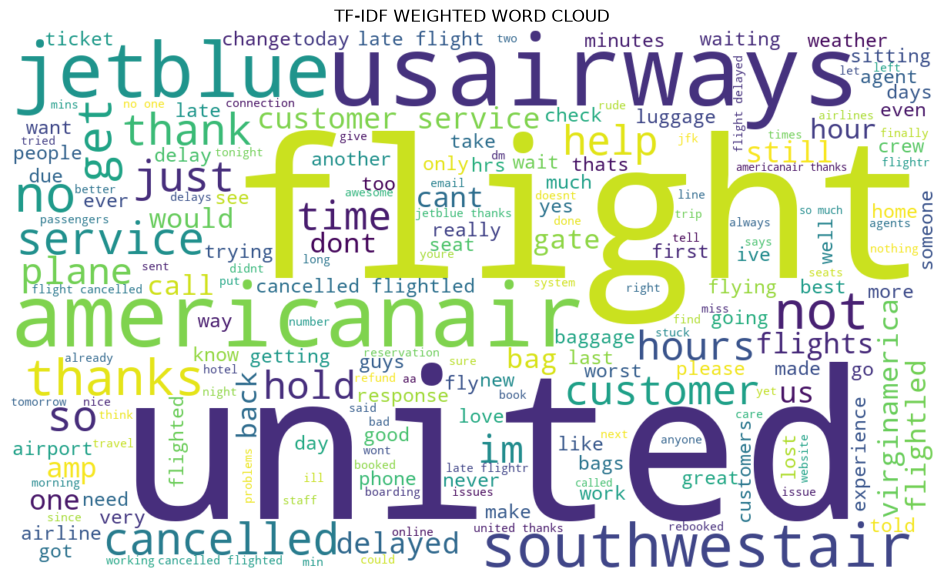

In [19]:
import matplotlib.pyplot as plt

from wordcloud import WordCloud  
tfidf_scores = np.asarray(final_tfidf.sum(axis = 0)).ravel()
feature_names = tfidf_vectorizer.get_feature_names_out()
word_scores = dict(zip(feature_names, tfidf_scores))
wc = WordCloud(width = 1200, height = 700, background_color = 'white')
wc.generate_from_frequencies(word_scores)
plt.figure(figsize = (12,7))
plt.imshow(wc, interpolation = 'bilinear') 
plt.axis('off')
plt.title("TF-IDF WEIGHTED WORD CLOUD")
plt.show()



In [20]:
feature_names

array(['aa', 'ability', 'able', ..., 'yup', 'yyz', 'zero'],
      shape=(5000,), dtype=object)

In [21]:
final['label']

0       0
1       0
2       0
3       0
4       0
       ..
9227    0
9228    0
9229    0
9230    0
9231    0
Name: label, Length: 9134, dtype: int64

In [22]:
x_train = final_tfidf 
y_train = final['label']
from sklearn.naive_bayes import MultinomialNB 
model = MultinomialNB()
model.fit(x_train, y_train)

,"alpha alpha: float or array-like of shape (n_features,), default=1.0Additive (Laplace/Lidstone) smoothing parameter(set alpha=0 and force_alpha=True, for no smoothing).",1.0
,"force_alpha force_alpha: bool, default=TrueIf False and alpha is less than 1e-10, it will set alpha to1e-10. If True, alpha will remain unchanged. This may causenumerical errors if alpha is too close to 0... versionadded:: 1.2.. versionchanged:: 1.4 The default value of `force_alpha` changed to `True`.",True
,"fit_prior fit_prior: bool, default=TrueWhether to learn class prior probabilities or not.If false, a uniform prior will be used.",True
,"class_prior class_prior: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)Number of samples encountered for each class during fitting. Thisvalue is weighted by the sample weight when provided.","ndarray[float64](2,)","[7287.,1847.]"
"class_log_prior_ class_log_prior_: ndarray of shape (n_classes,)Smoothed empirical log probability for each class.","ndarray[float64](2,)","[-0.23,-1.6 ]"
"classes_ classes_: ndarray of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"feature_count_ feature_count_: ndarray of shape (n_classes, n_features)Number of samples encountered for each (class, feature)during fitting. This value is weighted by the sample weight whenprovided.","ndarray[float64](2, 5000)","[[22.84, 1.59,14.48,..., 0.81, 3.19, 7.36], [ 4.59, 0.33, 7.08,..., 1.19, 0.82, 0.38]]"
"feature_log_prob_ feature_log_prob_: ndarray of shape (n_classes, n_features)Empirical log probability of featuresgiven a class, ``P(x_i|y)``.","ndarray[float64](2, 5000)","[[-7.11,-9.33,-7.54,...,-9.69,-8.85,-8.16], [-7.51,-8.94,-7.14,...,-8.44,-8.63,-8.91]]"
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,5000


# Testing for TF-IDF and MultinomialNB

In [23]:
final_test = test_df.drop_duplicates(subset = {"text","airline","label"})


In [24]:
from tqdm import tqdm 
preprocessed_reviews_testing = [] 
for sentence in tqdm(final_test['text'].values):
  text = str(sentence).lower()
  text = re.sub(r'[^a-zA-Z0-9\s]', '', text)
  text = re.sub(r"http\S+|www\S+", "", text)
  text = re.sub(r'\S*\d\S*', '', text).strip()
  text = re.sub(r'@\W+', '', text)
  text = re.sub(r'\s+', ' ', text).strip() 
  text = BeautifulSoup(text, "html.parser").get_text()
  text = ' '.join(e for e in text.split() if e not in stop_words)  
  preprocessed_reviews_testing.append(text.strip())


100%|██████████| 2304/2304 [00:00<00:00, 16998.79it/s]


In [25]:
preprocessed_reviews_testing

['usairways agent not say',
 'united overbooked fifty people worst',
 'united friendly efficient air attendants coach',
 'united considering im stuck newark virtually sleep hours doubt hope car rentals available',
 'usairways worst trip little no customer service',
 'united not mind getting next flight',
 'southwestair guys held flight thank take mdw oakland thanks',
 'virginamerica hi just bked cool birthday trip cant add elevate no cause entered middle name flight booking problems',
 'usairways happening flight bos phl daughter fiance stuck bos',
 'usairways didnt even leave airport sent bags philadelphia',
 'southwestair although wait long due weather rscheduling phone call super rep solved issue thank',
 'united please provide update ua flight stranded united no information crew plane',
 'united proof situation due company mistake',
 'united u not gate ready gate agent going hour two',
 'united frozen lines flight not continuing due passenger comfort not ok sat plane long flight ve

In [26]:
final_test['cleaned_text'] = preprocessed_reviews_testing

In [27]:
final_test

,text,airline,label,cleaned_text
0,@USAirways your agent did not say,US Airways,0,usairways agent not say
1,@united overbooked by FIFTY people?!? the worst.,United,0,united overbooked fifty people worst
2,@united … But friendly efficient air attendant...,United,0,united friendly efficient air attendants coach
3,@united considering I'm now stuck in Newark wi...,United,0,united considering im stuck newark virtually s...
4,@USAirways this has been the worst trip with l...,US Airways,0,usairways worst trip little no customer service
...,...,...,...,...
2304,"@JetBlue you stood me up last night, but I'm g...",Delta,0,jetblue stood last night im giving second chan...
2305,@usairways Is your reservation phone number wo...,US Airways,0,usairways reservation phone number working cal...
2306,"@USAirways @msscottwg ""That's unusual"" means ...",US Airways,0,usairways msscottwg thats unusual means screwe...
2307,@SouthwestAir I've been on hold for 2 hours! ...,Southwest,0,southwestair ive hold hours answer


In [28]:
x_test = tfidf_vectorizer.transform(preprocessed_reviews_testing)
y_test = final_test['label']
y_pred = model.predict(x_test)
print("Accuracy", accuracy_score(y_test, y_pred)) 
print("Precision", precision_score(y_test, y_pred, average = 'macro')) 

Accuracy 0.8854166666666666
Precision 0.9131608737579138


# Word2vec

In [29]:
from nltk.tokenize import word_tokenize
negative_words = final[final['label'] == 0]['cleaned_text'].values
tokenized_words = [ word_tokenize(text) for text in negative_words if isinstance(text,str)]

In [30]:
tokenized_words

[['jetblue',
  'finally',
  'starting',
  'come',
  'minutes',
  'no',
  'communication',
  'not',
  'acceptable',
  'letting',
  'today'],
 ['usairways',
  'oh',
  'got',
  'right',
  'agent',
  'just',
  'kept',
  'putting',
  'hold',
  'still',
  'didnt',
  'fix',
  'problem'],
 ['americanair',
  'idea',
  'wait',
  'time',
  'refunds',
  'usairways',
  'told',
  'days',
  'phone',
  'well',
  'past'],
 ['americanair', 'priority', 'baggage', 'evidently', 'means', 'comes', 'last'],
 ['usairways', 'youre', 'really', 'fudgin', 'delays', 'justwantmybed'],
 ['americanair',
  'supposed',
  'depart',
  'central',
  'ready',
  'close',
  'door',
  'central'],
 ['americanair',
  'guys',
  'dfw',
  'stuck',
  'gate',
  'half',
  'hour',
  'pull',
  'slide'],
 ['united',
  'exhausted',
  'amp',
  'frustrated',
  'link',
  'fb',
  'post',
  'abt',
  'travel',
  'issue'],
 ['usairways',
  'already',
  'let',
  'know',
  'sent',
  'complaints',
  'got',
  'call',
  'back',
  'finally',
  'asleep'

In [31]:
from gensim.models import Word2Vec 
sample_reviews = tokenized_words 

In [32]:
w2v_model = Word2Vec(sentences = sample_reviews, vector_size = 100, window = 5, min_count = 3, workers = 5, sg = 1 )


In [33]:
def get_sentence_vector(tokens, model):
    vectors = [model.wv[word] for word in tokens if word in model.wv]  
    if len(vectors) == 0 :
        return np.zeros(model.vector_size)
    return np.mean(vectors, axis = 0)
sample_reviews  = tokenized_words 
review_vectors = np.array([get_sentence_vector(tokens, w2v_model) for tokens in sample_reviews]) 




In [34]:
print(review_vectors.shape)

(7287, 100)


# KMeans CLustering

In [35]:
from sklearn.cluster import KMeans

In [36]:
import pandas as pd

In [37]:
negative_indices = final[final['label'] == 0]['cleaned_text'].dropna().index
negative_indices[:10]

Index([0, 1, 2, 3, 4, 5, 6, 7, 8, 9], dtype='int64')

In [38]:
for k in [3,4,5]:
    kmeans = KMeans(n_clusters = k, random_state = 42)
    clusters = kmeans.fit_predict(review_vectors)
    cluster_series_aligned = pd.Series(clusters, index = negative_indices) 
    final['Cluster_Word2Vec'] = cluster_series_aligned 
    print(final['Cluster_Word2Vec'].value_counts())
    print(final[final['label'] == 0][['cleaned_text', 'Cluster_Word2Vec']].head(10))

Cluster_Word2Vec
0.0    3050
1.0    2791
2.0    1446
Name: count, dtype: int64
                                        cleaned_text  Cluster_Word2Vec
0  jetblue finally starting come minutes no commu...               1.0
1  usairways oh got right agent just kept putting...               1.0
2  americanair idea wait time refunds usairways t...               1.0
3  americanair priority baggage evidently means c...               0.0
4  usairways youre really fudgin delays justwantm...               0.0
5  americanair supposed depart central ready clos...               1.0
6  americanair guys dfw stuck gate half hour pull...               1.0
7  united exhausted amp frustrated link fb post a...               0.0
8  usairways already let know sent complaints got...               1.0
9  usairways guys luggage san jose supposed deliv...               1.0
Cluster_Word2Vec
0.0    2848
1.0    2618
2.0     975
3.0     846
Name: count, dtype: int64
                                        cleaned_t

In [39]:
from sklearn.decomposition import PCA
import seaborn as sns

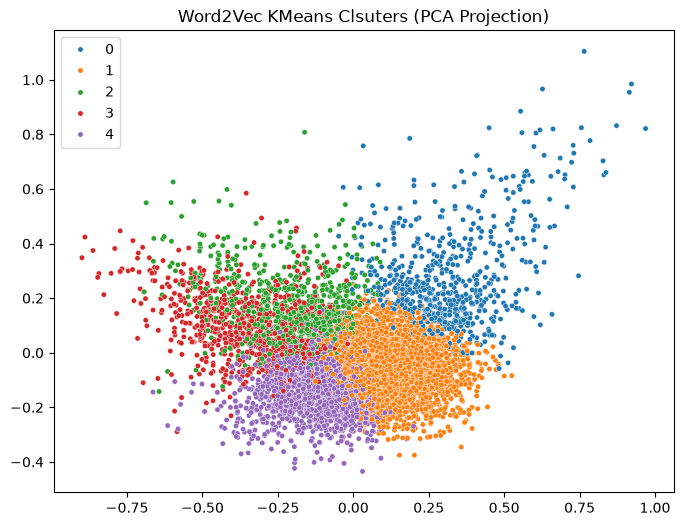

In [40]:
sample_size = min(10000, len(review_vectors))
sample_idx = np.random.choice(len(review_vectors), size = sample_size, replace = False)
pca = PCA(n_components = 2, random_state = 42)
pca_projection = pca.fit_transform(review_vectors[sample_idx])
sample_clusters = clusters[sample_idx]
plt.figure(figsize = (8,6)) 
sns.scatterplot(
    x = pca_projection[:,0],
    y = pca_projection[:,1],
    hue = sample_clusters,
    palette = 'tab10',
    s = 15
)
plt.title("Word2Vec KMeans Clsuters (PCA Projection)")
plt.show()

In [41]:
from sklearn.metrics.pairwise import cosine_similarity

In [52]:
from nltk.corpus import stopwords

stop_words = set(stopwords.words("english"))

In [65]:
def retrival_tfidf(query, top_k = 5):
    query = re.sub(r"http\S+", "", query)
    query = BeautifulSoup(query, "html.parser").get_text()
    query = re.sub("\S*\d\S*", "", query).strip()
    query = re.sub(r'[^A-Za-z]+', ' ', query)
    query_tokens = ' '.join(e.lower()for e in query.split() if e.lower() not in stop_words) 
    #converting query to tfidf vectorizer 
    query_vec = tfidf_vectorizer.transform([query_tokens])
    similarity = cosine_similarity(query_vec, final_tfidf).flatten()
    top_indices = similarity.argsort()[::-1][:top_k]
    return final.iloc[top_indices][['cleaned_text', 'label']], similarity[top_indices]

    
    

In [67]:
query = "us still didnt fix problem"
top_reviews, scores = retrival_tfidf(query, top_k = 5)
for i, (review, score) in enumerate(zip(top_reviews['cleaned_text'], scores)):
    print(f"Review {i+1} (Label: {top_reviews['label'].iloc[i]}):\n{review}\nSimilarity Score: {score:.3f}\n{'-'*80}")

Review 1 (Label: 0):
usairways oh got right agent just kept putting hold still didnt fix problem
Similarity Score: 0.537
--------------------------------------------------------------------------------
Review 2 (Label: 0):
united houstonbogota engine problem mechanics trying fix problem safety first better change plane
Similarity Score: 0.504
--------------------------------------------------------------------------------
Review 3 (Label: 1):
americanair ltaljx dca oma morning staff helped fix problem so helpful goodthingscome thanks
Similarity Score: 0.485
--------------------------------------------------------------------------------
Review 4 (Label: 0):
usairways gladly take loyal customers money cause inconvenience nothing help fix problem caused
Similarity Score: 0.364
--------------------------------------------------------------------------------
Review 5 (Label: 0):
usairways time bracket call fix problemive attempting fix contact information issue days
Similarity Score: 0.273

# Word2Vec Semantic search

In [80]:
final = train_df.drop_duplicates(subset=["text", "airline", "label"]).copy()
final['cleaned_text'] = preprocessed_reviews
reviews = final['cleaned_text'].astype(str).to_numpy()


In [81]:
reviews

array(['jetblue finally starting come minutes no communication not acceptable letting today',
       'usairways oh got right agent just kept putting hold still didnt fix problem',
       'americanair idea wait time refunds usairways told days phone well past',
       ...,
       'usairways no flights philly system wide tech issue cbsphilly',
       'united customer service sucks hang waiting hour talking minutes',
       'usairways paid seat expect able use full seat'],
      shape=(9134,), dtype=object)

In [82]:
tokenized_corpus = [word_tokenize(text.lower()) for text in reviews]

In [83]:
tokenized_corpus

[['jetblue',
  'finally',
  'starting',
  'come',
  'minutes',
  'no',
  'communication',
  'not',
  'acceptable',
  'letting',
  'today'],
 ['usairways',
  'oh',
  'got',
  'right',
  'agent',
  'just',
  'kept',
  'putting',
  'hold',
  'still',
  'didnt',
  'fix',
  'problem'],
 ['americanair',
  'idea',
  'wait',
  'time',
  'refunds',
  'usairways',
  'told',
  'days',
  'phone',
  'well',
  'past'],
 ['americanair', 'priority', 'baggage', 'evidently', 'means', 'comes', 'last'],
 ['usairways', 'youre', 'really', 'fudgin', 'delays', 'justwantmybed'],
 ['americanair',
  'supposed',
  'depart',
  'central',
  'ready',
  'close',
  'door',
  'central'],
 ['americanair',
  'guys',
  'dfw',
  'stuck',
  'gate',
  'half',
  'hour',
  'pull',
  'slide'],
 ['united',
  'exhausted',
  'amp',
  'frustrated',
  'link',
  'fb',
  'post',
  'abt',
  'travel',
  'issue'],
 ['usairways',
  'already',
  'let',
  'know',
  'sent',
  'complaints',
  'got',
  'call',
  'back',
  'finally',
  'asleep'

In [86]:
w2v_model_v2 = Word2Vec(sentences = tokenized_corpus, vector_size = 100, window = 5, min_count = 2, workers = 5, sg = 1)

In [89]:
def get_sentence_vector_two(sentence, model):
    vec = [model.wv[word] for word in sentence if word in model.wv] 
    if len(vec) == 0:
        return np.zeros(model.vector_size)
    return np.mean(vec, axis = 0)
sentence_vectors_two = np.array([get_sentence_vector_two(sent, w2v_model_v2) for sent in tokenized_corpus])

In [98]:
query = "fix problem"
query_tokens_two = query.lower().split()
query_vec_two = get_sentence_vector_two(query_tokens_two, w2v_model_v2)
similarities_two = cosine_similarity([query_vec_two], sentence_vectors_two).flatten()
top_k = 5 
top_indices_two = similarities_two.argsort()[-top_k:][::-1]
print(f"Top-{top_k} reviews for query '{query}':")
for idx in top_indices_two:
    print(f"Score = {similarities_two[idx]:.3f}") 
    print(final.iloc[idx]['cleaned_text'])
    print("-"* 8)

Top-5 reviews for query 'fix problem':
Score = 0.995
usairways gladly take loyal customers money cause inconvenience nothing help fix problem caused
--------
Score = 0.995
americanair dont send tweet cover social media complaints sending message way resolve custserv
--------
Score = 0.994
southwestair way give voice customers pay services not satisfactorily delivered justsayin
--------
Score = 0.994
southwestair agents werenot helpful told would pay even though tld bwi whch part trvl advsry
--------
Score = 0.994
americanair thx apology commitment fix broken system would better actually fixing would better still
--------
